# Mini-projet IoT — Sujet 10 : Suivi d'activité physique simulé

**Objectif :** créer un système logiciel qui simule le nombre de pas d'un utilisateur (comme un bracelet connecté / podomètre), analyse son activité au cours de la journée et l'aide à atteindre un objectif quotidien.

**Environnement :** Python 3 · NumPy · Pandas · Matplotlib — exécutable dans Google Colab ou Jupyter. Aucun matériel réel, aucune donnée médicale réelle.

**Groupe :** _(noms des membres)_

### Plan
1. **Étape 1 – Modélisation** : problème, utilisateurs, capteurs virtuels, architecture, hypothèses
2. **Étape 2 – Génération des données** : 14 jours de mesures horaires (situations normale, limite, anormale)
3. **Étape 3 – Traitement et décision** : nettoyage, règles de notification, objectif configurable, 3 stratégies comparées
4. **Étape 4 – Analyse** : graphiques, indicateurs, interprétation, limites et améliorations

## Étape 1 – Modélisation

### 1.1 Problème et utilisateurs
Beaucoup de personnes (étudiants, employés de bureau) restent assises de longues heures sans s'en rendre compte. L'OMS recommande de bouger régulièrement ; un repère courant est de viser **entre 7 000 et 10 000 pas par jour**.

**Utilisateur concerné :** une personne qui porte un bracelet connecté et veut suivre son activité quotidienne.
**Autres acteurs possibles :** un coach sportif, un service de santé au travail (avec des données anonymisées).

### 1.2 Composants du système IoT

| Couche IoT | Élément simulé | Représentation Python |
|---|---|---|
| **Capteur** | Accéléromètre / podomètre du bracelet | fonction `capteur_podometre()` : pas réels + erreur de mesure + pannes |
| **Transmission** | Synchronisation Bluetooth bracelet → smartphone, une fois par heure | une ligne du DataFrame par heure |
| **Traitement** | Validation, nettoyage, cumul, calcul des indicateurs | fonctions `valider_mesure()`, `nettoyer()`, `simuler()` |
| **Décision** | Règles : inactivité, retard sur l'objectif, objectif atteint | fonction `regles_decision()` |
| **Actionneur** | Vibration du bracelet + notification sur le téléphone | colonne `notification` + effet sur le comportement |
| **Application** | Tableau de bord journalier | graphiques Matplotlib |

### 1.3 Données produites (une ligne = une heure)

| Variable | Unité | Description |
|---|---|---|
| `date`, `heure` | — / h (0–23) | horodatage de la mesure |
| `type_jour` | — | semaine, weekend, limite (journée sédentaire), anormal (capteur défaillant) |
| `etat` | — | état d'activité simulé : sommeil, repos, léger, marche, sport |
| `pas_reels` | pas/h | pas réellement effectués (inconnus du système, servent à vérifier) |
| `pas_mesures` | pas/h | valeur envoyée par le capteur (peut être erronée ou manquante) |
| `anomalie` | — | type d'erreur détectée : manquante, négative, aberrante |
| `pas_nettoyes` | pas/h | valeur après nettoyage (utilisée pour l'analyse) |
| `cumul` | pas | pas cumulés depuis minuit |
| `progression` | % | cumul / objectif du jour |
| `minutes_actives` | min | durée active estimée (pas ÷ 100 pas/min) |
| `notification` | — | message envoyé au bracelet (vide sinon) |

In [1]:
# ============================================================
# Importations et paramètres configurables
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Graine aléatoire : on obtient toujours les mêmes résultats (reproductibilité)
GRAINE = 42

# --- Paramètres de la simulation ---
NB_JOURS = 14                       # 2 semaines de suivi
DATE_DEBUT = "2026-11-02"           # un lundi

# --- Objectif quotidien CONFIGURABLE (modifier ici) ---
OBJECTIF_QUOTIDIEN = 8000           # pas / jour

# --- Paramètres de l'objectif adaptatif (stratégie C) ---
OBJECTIF_MIN, OBJECTIF_MAX = 6000, 10000   # bornes en pas/jour
FACTEUR_PROGRES = 1.05                     # +5 % par rapport à la moyenne récente

# --- Paramètres des règles de décision ---
CADENCE_ACTIVE = 100                # pas/min : cadence d'une marche normale
SEUIL_SEDENTAIRE = 250              # pas/h en dessous duquel une heure est "sédentaire"
NB_HEURES_INACTIVES = 3             # heures sédentaires consécutives avant une alerte
HEURES_EVEIL = range(9, 21)         # plage où l'on surveille l'inactivité (9h-20h)
HEURE_BILAN = 18                    # heure de vérification du retard sur l'objectif
SEUIL_RETARD = 0.60                 # alerte si < 60 % de l'objectif à 18h
PAS_MAX_HORAIRE = 12000             # limite physique : 200 pas/min pendant 60 min
P_REACTION = 0.5                    # probabilité que l'utilisateur réagisse à une notification

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Objectif quotidien :", OBJECTIF_QUOTIDIEN, "pas")

Matplotlib is building the font cache; this may take a moment.


Objectif quotidien : 8000 pas


### 1.4 Architecture simplifiée du système IoT

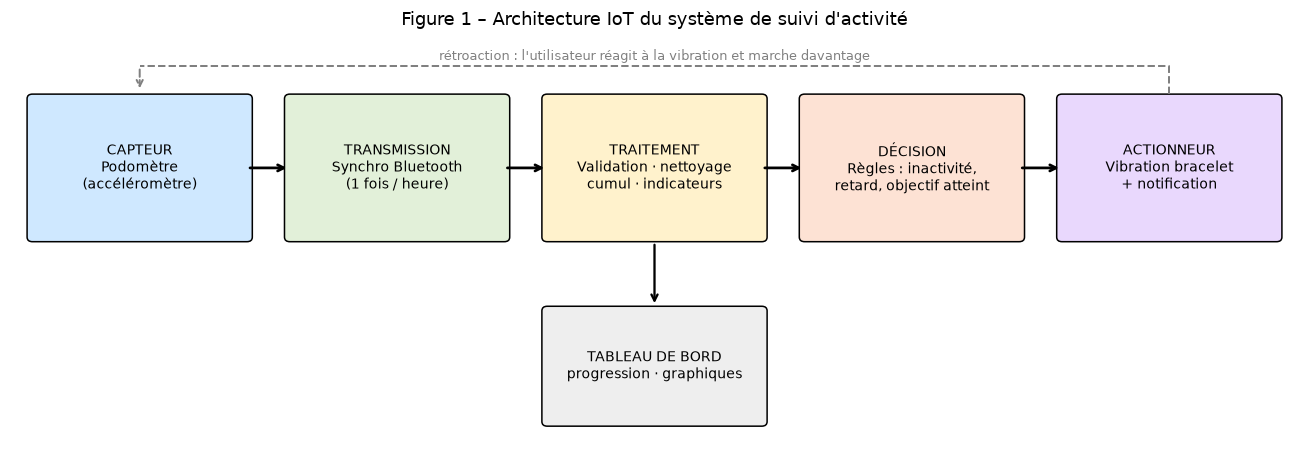

In [2]:
# Schéma d'architecture dessiné avec Matplotlib
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.4); ax.axis("off")

blocs = [
    (0.2, "CAPTEUR\nPodomètre\n(accéléromètre)", "#cfe8ff"),
    (2.6, "TRANSMISSION\nSynchro Bluetooth\n(1 fois / heure)", "#e2f0d9"),
    (5.0, "TRAITEMENT\nValidation · nettoyage\ncumul · indicateurs", "#fff2cc"),
    (7.4, "DÉCISION\nRègles : inactivité,\nretard, objectif atteint", "#fde2d4"),
    (9.8, "ACTIONNEUR\nVibration bracelet\n+ notification", "#e9d8fd"),
]
for x, texte, couleur in blocs:
    ax.add_patch(mpatches.FancyBboxPatch((x, 2.2), 2.0, 1.5, boxstyle="round,pad=0.05",
                                         fc=couleur, ec="black"))
    ax.text(x + 1.0, 2.95, texte, ha="center", va="center", fontsize=9)
for x in (2.2, 4.6, 7.0, 9.4):
    ax.annotate("", xy=(x + 0.4, 2.95), xytext=(x, 2.95),
                arrowprops=dict(arrowstyle="->", lw=1.8))

# Tableau de bord + boucle de rétroaction
ax.add_patch(mpatches.FancyBboxPatch((5.0, 0.2), 2.0, 1.2, boxstyle="round,pad=0.05",
                                     fc="#eeeeee", ec="black"))
ax.text(6.0, 0.8, "TABLEAU DE BORD\nprogression · graphiques", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(6.0, 1.45), xytext=(6.0, 2.15), arrowprops=dict(arrowstyle="->", lw=1.5))
# Boucle de rétroaction : de l'actionneur vers le capteur, par le haut
ax.plot([10.8, 10.8, 1.2], [3.75, 4.05, 4.05], ls="--", color="gray", lw=1.3)
ax.annotate("", xy=(1.2, 3.78), xytext=(1.2, 4.05),
            arrowprops=dict(arrowstyle="->", lw=1.3, ls="--", color="gray"))
ax.text(6.0, 4.12, "rétroaction : l'utilisateur réagit à la vibration et marche davantage",
        fontsize=8.5, color="gray", ha="center")
ax.set_title("Figure 1 – Architecture IoT du système de suivi d'activité", fontsize=12)
plt.tight_layout(); plt.savefig("figures/fig1_architecture.png"); plt.show()

### 1.5 Hypothèses de simulation
- **H1.** Le bracelet transmet **un total de pas par heure** (24 mesures par jour).
- **H2.** Chaque heure, l'utilisateur est dans un **état d'activité** (sommeil, repos, léger, marche, sport) tiré au hasard selon des probabilités qui dépendent de l'heure et du type de journée.
- **H3.** Le nombre de pas dépend de l'état : sommeil ≈ 0, repos ≈ 80, léger ≈ 500, marche ≈ 1 800, sport ≈ 4 500 pas/h (avec une variation aléatoire).
- **H4.** Le capteur a une **erreur de mesure de ±3 %** ; certains jours il tombe en panne (batterie vide, perte de synchronisation, valeurs impossibles).
- **H5.** La **durée active** est estimée par `pas ÷ 100 pas/min` (cadence d'une marche normale), plafonnée à 60 min/h.
- **H6.** Quand le bracelet vibre, l'utilisateur réagit dans **50 %** des cas en marchant l'heure suivante (petite marche après une alerte d'inactivité, marche plus longue après une alerte de retard).

## Étape 2 – Génération des données

### 2.1 Modèle d'activité
Pour chaque heure, on choisit un état d'activité avec des probabilités qui dépendent de l'heure et du type de journée :
- **semaine** (situation **normale**) : trajets le matin (7–8h) et le soir (17–18h), pause déjeuner, sport possible en soirée ;
- **weekend** (situation **normale**, plus variable) : lever tardif, sorties l'après-midi ;
- **limite** : journée très sédentaire (révisions, télétravail, pluie) ;
- **anormal** : journée de semaine normale, mais le **capteur est défaillant**.

In [3]:
ETATS = ["sommeil", "repos", "leger", "marche", "sport"]

# Nombre de pas par heure selon l'état : (moyenne, écart-type)
PAS_PAR_ETAT = {
    "sommeil": (5, 5),
    "repos":   (80, 30),
    "leger":   (500, 150),
    "marche":  (1800, 400),
    "sport":   (4500, 900),
}

def probas_etats(heure, type_jour):
    # Retourne les probabilités [sommeil, repos, leger, marche, sport] pour une heure donnée.
    if type_jour in ("semaine", "anormal"):
        if heure <= 5 or heure == 23:   return [0.97, 0.03, 0.00, 0.00, 0.00]
        if heure == 6:                  return [0.50, 0.30, 0.20, 0.00, 0.00]
        if heure in (7, 8, 17, 18):     return [0.00, 0.20, 0.40, 0.40, 0.00]  # trajets
        if heure in (12, 13):           return [0.00, 0.30, 0.40, 0.30, 0.00]  # pause déjeuner
        if heure in (19, 20):           return [0.00, 0.45, 0.30, 0.10, 0.15]  # sport possible
        if 9 <= heure <= 16:            return [0.00, 0.70, 0.25, 0.05, 0.00]  # cours / bureau
        return [0.10, 0.60, 0.30, 0.00, 0.00]                                   # 21h-22h
    if type_jour == "weekend":
        if heure <= 7 or heure == 23:   return [0.97, 0.03, 0.00, 0.00, 0.00]
        if heure == 8:                  return [0.50, 0.40, 0.10, 0.00, 0.00]
        if 9 <= heure <= 11:            return [0.00, 0.40, 0.40, 0.15, 0.05]
        if heure in (12, 13):           return [0.00, 0.50, 0.40, 0.10, 0.00]
        if 14 <= heure <= 18:           return [0.00, 0.35, 0.35, 0.25, 0.05]  # sorties
        return [0.00, 0.60, 0.30, 0.10, 0.00]                                   # 19h-22h
    if type_jour == "limite":
        if heure <= 6 or heure == 23:   return [0.97, 0.03, 0.00, 0.00, 0.00]
        if heure in (12, 13):           return [0.00, 0.60, 0.40, 0.00, 0.00]
        return [0.00, 0.85, 0.15, 0.00, 0.00]                                   # assis toute la journée
    raise ValueError("type de jour inconnu : " + type_jour)

# Vérification : chaque ligne de probabilités doit faire 1
for t in ("semaine", "weekend", "limite", "anormal"):
    for h in range(24):
        assert abs(sum(probas_etats(h, t)) - 1) < 1e-9, (t, h)
print("Probabilités vérifiées ✔")

Probabilités vérifiées ✔


In [4]:
# Calendrier des 14 jours : type de chaque journée
dates = pd.date_range(DATE_DEBUT, periods=NB_JOURS, freq="D")
types_jours = []
for d in dates:
    types_jours.append("weekend" if d.dayofweek >= 5 else "semaine")

# Scénarios particuliers (situations limite et anormale)
types_jours[3] = "anormal"   # jeudi semaine 1 : batterie vide + pic aberrant
types_jours[4] = "limite"    # vendredi semaine 1 : journée de pluie, très peu de marche
types_jours[9] = "limite"    # mercredi semaine 2 : révision d'examen
types_jours[11] = "anormal"  # vendredi semaine 2 : perte de synchro + valeur négative

NOMS_JOURS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
calendrier = pd.DataFrame({
    "date": dates.date,
    "jour": [NOMS_JOURS[d.dayofweek] for d in dates],
    "type_jour": types_jours,
})
calendrier

C:\Users\DELL\AppData\Local\Temp\ipykernel_11884\3587531710.py:5: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  types_jours.append("weekend" if d.dayofweek >= 5 else "semaine")
C:\Users\DELL\AppData\Local\Temp\ipykernel_11884\3587531710.py:16: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "jour": [NOMS_JOURS[d.dayofweek] for d in dates],


,date,jour,type_jour
0,2026-11-02,lun,semaine
1,2026-11-03,mar,semaine
2,2026-11-04,mer,semaine
3,2026-11-05,jeu,anormal
4,2026-11-06,ven,limite
5,2026-11-07,sam,weekend
6,2026-11-08,dim,weekend
7,2026-11-09,lun,semaine
8,2026-11-10,mar,semaine
9,2026-11-11,mer,limite


### 2.2 Génération des pas réels
On génère d'abord ce que l'utilisateur fait **réellement** (vérité terrain). Le système, lui, ne verra que les mesures du capteur.

In [5]:
rng = np.random.default_rng(GRAINE)

def generer_pas_reels(type_jour):
    # Simule une journée : 24 états d'activité et 24 nombres de pas réels.
    etats, pas = [], []
    for h in range(24):
        etat = rng.choice(ETATS, p=probas_etats(h, type_jour))
        moyenne, ecart = PAS_PAR_ETAT[etat]
        n = max(0, int(rng.normal(moyenne, ecart)))   # pas de valeur négative
        etats.append(etat)
        pas.append(n)
    return etats, pas

lignes = []
for _, j in calendrier.iterrows():
    etats, pas = generer_pas_reels(j["type_jour"])
    for h in range(24):
        lignes.append({"date": j["date"], "jour": j["jour"], "type_jour": j["type_jour"],
                       "heure": h, "etat": etats[h], "pas_base": pas[h]})
base = pd.DataFrame(lignes)

# Tirages aléatoires préparés à l'avance (identiques pour toutes les stratégies => comparaison équitable)
base["bruit_capteur"] = rng.normal(1.0, 0.03, len(base))    # erreur de mesure ±3 %
base["tirage_reaction"] = rng.random(len(base))              # l'utilisateur réagit-il ?
base["pas_reaction_courte"] = rng.normal(600, 150, len(base)).clip(0)   # après alerte inactivité
base["pas_reaction_longue"] = rng.normal(1500, 300, len(base)).clip(0)  # après alerte de retard

print(base.shape[0], "mesures horaires générées (", NB_JOURS, "jours x 24 h )")
base.head(10)

336 mesures horaires générées ( 14 jours x 24 h )


,date,jour,type_jour,heure,etat,pas_base,bruit_capteur,tirage_reaction,pas_reaction_courte,pas_reaction_longue
0,2026-11-02,lun,semaine,0,sommeil,0,0.966888,0.659996,515.886875,972.055288
1,2026-11-02,lun,semaine,1,sommeil,9,1.017618,0.302480,596.662831,1725.538940
2,2026-11-02,lun,semaine,2,sommeil,0,1.009582,0.947536,365.567348,1538.586478
3,2026-11-02,lun,semaine,3,sommeil,3,0.973929,0.366335,634.315504,2216.085540
4,2026-11-02,lun,semaine,4,sommeil,0,1.005322,0.738511,745.119941,1169.959334
5,2026-11-02,lun,semaine,5,sommeil,8,1.036376,0.403140,643.940074,1469.201373
6,2026-11-02,lun,semaine,6,repos,113,0.990286,0.561819,361.665365,2039.486310
7,2026-11-02,lun,semaine,7,leger,371,0.949241,0.719783,581.428606,1857.416892
8,2026-11-02,lun,semaine,8,leger,356,0.999473,0.508934,711.304335,1291.136385
9,2026-11-02,lun,semaine,9,leger,492,0.972927,0.907086,318.301685,1567.190229


### 2.3 Capteur virtuel (podomètre) et pannes simulées
Le capteur ajoute une petite erreur de mesure. Les journées **anormales** contiennent des pannes typiques d'un objet connecté :

| Jour | Panne simulée | Effet sur la mesure |
|---|---|---|
| jeudi 05/11 | batterie vide de 14h à 17h | valeurs **manquantes** (NaN) |
| jeudi 05/11 | bug du capteur à 8h | valeur **aberrante** (25 000 pas en 1 h) |
| vendredi 13/11 | perte de synchronisation de 9h à 11h | valeurs **manquantes** |
| vendredi 13/11 | erreur de transmission à 15h | valeur **négative** (−350) |

In [6]:
# Pannes injectées : (indice du jour, heure) -> valeur transmise
PANNES = {
    (3, 14): np.nan, (3, 15): np.nan, (3, 16): np.nan, (3, 17): np.nan,  # batterie vide
    (3, 8): 25000,                                                       # pic aberrant
    (11, 9): np.nan, (11, 10): np.nan, (11, 11): np.nan,                 # perte de synchro
    (11, 15): -350,                                                      # valeur négative
}
index_jour = {d: i for i, d in enumerate(calendrier["date"])}

def capteur_podometre(ligne, pas_reels):
    # Retourne la valeur transmise par le bracelet pour une heure donnée.
    cle = (index_jour[ligne["date"]], ligne["heure"])
    if cle in PANNES:
        return PANNES[cle]
    return round(pas_reels * ligne["bruit_capteur"])

## Étape 3 – Traitement et décision

### 3.1 Validation et nettoyage des mesures
Une mesure est **valide** si elle existe et si elle est comprise entre 0 et `PAS_MAX_HORAIRE` (12 000 pas/h, soit 200 pas/min pendant une heure entière : au-delà c'est physiquement impossible).

- **En temps réel** (dans le bracelet), une mesure invalide compte pour **0** : on préfère ne pas compter des pas douteux.
- **Pour l'analyse** (a posteriori), une mesure invalide est remplacée par la **médiane** des mesures valides à la même heure, les jours du même type.

In [7]:
def valider_mesure(valeur):
    # Retourne (est_valide, type_anomalie).
    if pd.isna(valeur):
        return False, "manquante"
    if valeur < 0:
        return False, "negative"
    if valeur > PAS_MAX_HORAIRE:
        return False, "aberrante"
    return True, ""

def nettoyer(df):
    # Remplace les mesures invalides par la médiane (même heure, même profil de journée).
    df = df.copy()
    profil = df["type_jour"].replace({"anormal": "semaine"})   # un jour anormal ressemble à un jour de semaine
    valides = df[df["valide"]]
    mediane = valides.groupby([profil[df["valide"]], "heure"])["pas_mesures"].median()
    df["pas_nettoyes"] = df["pas_mesures"].astype(float)
    for i in df.index[~df["valide"]]:
        df.loc[i, "pas_nettoyes"] = mediane[(profil[i], df.loc[i, "heure"])]
    df["pas_nettoyes"] = df["pas_nettoyes"].round().astype(int)
    return df

### 3.2 Règles de décision (actionneur = vibration du bracelet)

| Règle | Condition | Action |
|---|---|---|
| **R1 – Inactivité** | entre 9h et 20h, 3 heures consécutives avec moins de 250 pas/h | vibration « Levez-vous et marchez quelques minutes » |
| **R2 – Retard** | à 18h, cumul < 60 % de l'objectif | notification « Il vous reste X pas » |
| **R3 – Objectif atteint** | cumul ≥ objectif (une seule fois par jour) | notification de félicitations |

L'objectif du jour est soit **fixe** (`OBJECTIF_QUOTIDIEN`), soit **adaptatif** : 105 % de la moyenne des 7 derniers jours, borné entre 6 000 et 10 000 pas.

In [8]:
def regles_decision(h, historique_valide, cumul, objectif, deja_felicite, derniere_r1):
    # Applique R1, R2, R3 à la fin de l'heure h. Retourne (code_regle, message) ou (None, "").
    # R3 - objectif atteint
    if cumul >= objectif and not deja_felicite:
        return "R3", f"Bravo ! Objectif de {objectif} pas atteint"
    # R2 - retard sur l'objectif à 18h
    if h == HEURE_BILAN and cumul < SEUIL_RETARD * objectif:
        return "R2", f"Il vous reste {objectif - cumul} pas pour atteindre l'objectif"
    # R1 - inactivité prolongée (les heures avec mesure invalide ne déclenchent rien)
    if h in HEURES_EVEIL and h - derniere_r1 >= NB_HEURES_INACTIVES:
        dernieres = historique_valide[-NB_HEURES_INACTIVES:]
        if len(dernieres) == NB_HEURES_INACTIVES and all(
                v is not None and v < SEUIL_SEDENTAIRE for v in dernieres):
            return "R1", "Inactif depuis 3 h : levez-vous et marchez quelques minutes"
    return None, ""


def calculer_objectif(strategie, totaux_precedents):
    if strategie["objectif"] == "fixe" or len(totaux_precedents) == 0:
        return OBJECTIF_QUOTIDIEN
    moyenne_7j = np.mean(totaux_precedents[-7:])
    return int(np.clip(round(FACTEUR_PROGRES * moyenne_7j, -2), OBJECTIF_MIN, OBJECTIF_MAX))


def simuler(strategie):
    # Simule les 14 jours heure par heure pour une stratégie donnée.
    resultats = []
    totaux_precedents = []
    for date, jour_df in base.groupby("date", sort=True):
        objectif = calculer_objectif(strategie, totaux_precedents)
        bonus = np.zeros(24)                 # pas supplémentaires provoqués par les notifications
        cumul, deja_felicite, derniere_r1 = 0, False, -99
        historique_valide = []
        for h, ligne in enumerate(jour_df.to_dict("records")):
            pas_reels = int(ligne["pas_base"] + bonus[h])
            mesure = capteur_podometre(ligne, pas_reels)          # 1) capteur
            valide, anomalie = valider_mesure(mesure)             # 2) validation
            valeur_tr = int(mesure) if valide else 0              # 3) traitement temps réel
            cumul += valeur_tr
            historique_valide.append(int(mesure) if valide else None)

            code_r, message = regles_decision(h, historique_valide, cumul, objectif,
                                              deja_felicite, derniere_r1)   # 4) décision
            envoyee = strategie["notifications"] and code_r is not None
            if code_r == "R3":
                deja_felicite = True
            if code_r == "R1":
                derniere_r1 = h
            # 5) actionneur : l'utilisateur réagit (ou pas) à la vibration
            if envoyee and code_r in ("R1", "R2") and h < 23 and ligne["tirage_reaction"] < P_REACTION:
                bonus[h + 1] += ligne["pas_reaction_courte"] if code_r == "R1" else ligne["pas_reaction_longue"]

            resultats.append({**ligne, "objectif": objectif, "pas_reels": pas_reels,
                              "pas_mesures": mesure, "valide": valide, "anomalie": anomalie,
                              "cumul_temps_reel": cumul, "alerte": code_r or "",
                              "notification": message if envoyee else ""})
        totaux_precedents.append(cumul)
    df = pd.DataFrame(resultats)
    df = nettoyer(df)
    df["cumul"] = df.groupby("date")["pas_nettoyes"].cumsum()
    df["progression"] = (100 * df["cumul"] / df["objectif"]).round(1)
    df["minutes_actives"] = (df["pas_nettoyes"] / CADENCE_ACTIVE).clip(upper=60).round(1)
    df["heure_sedentaire"] = df["heure"].isin(HEURES_EVEIL) & (df["pas_nettoyes"] < SEUIL_SEDENTAIRE)
    colonnes = ["date", "jour", "type_jour", "heure", "etat", "pas_reels", "pas_mesures", "valide",
                "anomalie", "pas_nettoyes", "cumul", "objectif", "progression", "minutes_actives",
                "heure_sedentaire", "alerte", "notification"]
    return df[colonnes]

### 3.3 Trois stratégies comparées
- **A – Suivi passif** : le bracelet compte les pas mais n'envoie aucune notification ; objectif fixe.
- **B – Notifications actives** : règles R1, R2, R3 activées ; objectif fixe.
- **C – Notifications + objectif adaptatif** : comme B, mais l'objectif s'adapte à l'activité récente.

In [9]:
STRATEGIES = {
    "A - Passif":            {"notifications": False, "objectif": "fixe"},
    "B - Notifications":     {"notifications": True,  "objectif": "fixe"},
    "C - Notif. + adaptatif": {"notifications": True,  "objectif": "adaptatif"},
}
sims = {nom: simuler(s) for nom, s in STRATEGIES.items()}
df = sims["B - Notifications"]          # stratégie principale pour les graphiques détaillés

pd.set_option("display.width", 200)
df[df["date"] == df["date"].iloc[0]].head(24)

,date,jour,type_jour,heure,etat,pas_reels,pas_mesures,valide,anomalie,pas_nettoyes,cumul,objectif,progression,minutes_actives,heure_sedentaire,alerte,notification
0,2026-11-02,lun,semaine,0,sommeil,0,0.0,True,,0,0,8000,0.0,0.0,False,,
1,2026-11-02,lun,semaine,1,sommeil,9,9.0,True,,9,9,8000,0.1,0.1,False,,
2,2026-11-02,lun,semaine,2,sommeil,0,0.0,True,,0,9,8000,0.1,0.0,False,,
3,2026-11-02,lun,semaine,3,sommeil,3,3.0,True,,3,12,8000,0.2,0.0,False,,
4,2026-11-02,lun,semaine,4,sommeil,0,0.0,True,,0,12,8000,0.2,0.0,False,,
5,2026-11-02,lun,semaine,5,sommeil,8,8.0,True,,8,20,8000,0.2,0.1,False,,
6,2026-11-02,lun,semaine,6,repos,113,112.0,True,,112,132,8000,1.6,1.1,False,,
7,2026-11-02,lun,semaine,7,leger,371,352.0,True,,352,484,8000,6.0,3.5,False,,
8,2026-11-02,lun,semaine,8,leger,356,356.0,True,,356,840,8000,10.5,3.6,False,,
9,2026-11-02,lun,semaine,9,leger,492,479.0,True,,479,1319,8000,16.5,4.8,False,,


In [10]:
def resume_journalier(d):
    # Agrège les mesures horaires en un tableau d'une ligne par jour.
    r = d.groupby(["date", "jour", "type_jour"], sort=True).agg(
        total_pas=("pas_nettoyes", "sum"),
        total_pas_reels=("pas_reels", "sum"),
        objectif=("objectif", "first"),
        minutes_actives=("minutes_actives", "sum"),
        heures_sedentaires=("heure_sedentaire", "sum"),
        nb_anomalies=("valide", lambda v: int((~v).sum())),
        nb_notifications=("notification", lambda s: int((s != "").sum())),
    ).reset_index()
    r["progression_%"] = (100 * r["total_pas"] / r["objectif"]).round(1)
    r["objectif_atteint"] = r["total_pas"] >= r["objectif"]
    r["minutes_actives"] = r["minutes_actives"].round(0).astype(int)
    return r

resumes = {nom: resume_journalier(d) for nom, d in sims.items()}
resume = resumes["B - Notifications"]
resume

,date,jour,type_jour,total_pas,total_pas_reels,objectif,minutes_actives,heures_sedentaires,nb_anomalies,nb_notifications,progression_%,objectif_atteint
0,2026-11-02,lun,semaine,8372,8494,8000,84,5,0,2,104.6,True
1,2026-11-03,mar,semaine,6821,6928,8000,68,8,0,1,85.3,False
2,2026-11-04,mer,semaine,10642,10638,8000,106,7,0,4,133.0,True
3,2026-11-05,jeu,anormal,5353,8021,8000,54,8,5,2,66.9,False
4,2026-11-06,ven,limite,4367,4388,8000,44,8,0,3,54.6,False
5,2026-11-07,sam,weekend,6869,6885,8000,69,8,0,3,85.9,False
6,2026-11-08,dim,weekend,7929,7983,8000,79,4,0,0,99.1,False
7,2026-11-09,lun,semaine,11854,11739,8000,119,4,0,1,148.2,True
8,2026-11-10,mar,semaine,10930,10995,8000,107,9,0,4,136.6,True
9,2026-11-11,mer,limite,2628,2662,8000,26,10,0,3,32.8,False


In [11]:
# Sauvegarde des données au format CSV (livrable)
df.to_csv("donnees_activite_horaires.csv", index=False, encoding="utf-8")
resume.to_csv("resume_journalier.csv", index=False, encoding="utf-8")
print("Fichiers créés : donnees_activite_horaires.csv (", len(df), "lignes ) et resume_journalier.csv")

Fichiers créés : donnees_activite_horaires.csv ( 336 lignes ) et resume_journalier.csv


### 3.4 Affichage de la progression vers l'objectif
Ce que l'utilisateur verrait dans son application à chaque synchronisation.

In [12]:
def afficher_progression(date, heure, d=df, largeur=20):
    ligne = d[(d["date"] == date) & (d["heure"] == heure)].iloc[0]
    p = min(ligne["progression"], 100)
    barre = "█" * int(p / 100 * largeur) + "░" * (largeur - int(p / 100 * largeur))
    print(f"{ligne['jour']} {date} - {heure:02d}h  {barre} {ligne['progression']:5.1f} %  "
          f"({ligne['cumul']:,} / {ligne['objectif']:,} pas)".replace(",", " "))

jour_exemple = calendrier["date"].iloc[0]
for h in (8, 12, 16, 18, 20, 23):
    afficher_progression(jour_exemple, h)

print("\nNotifications envoyées ce jour-là :")
print(df[(df["date"] == jour_exemple) & (df["notification"] != "")][["heure", "alerte", "notification"]]
      .to_string(index=False))

lun 2026-11-02 - 08h  ██░░░░░░░░░░░░░░░░░░  10.5 %  (840 / 8 000 pas)
lun 2026-11-02 - 12h  ████████████░░░░░░░░  62.8 %  (5 020 / 8 000 pas)
lun 2026-11-02 - 16h  ███████████████░░░░░  76.5 %  (6 123 / 8 000 pas)
lun 2026-11-02 - 18h  █████████████████░░░  85.8 %  (6 862 / 8 000 pas)
lun 2026-11-02 - 20h  █████████████████░░░  88.1 %  (7 051 / 8 000 pas)
lun 2026-11-02 - 23h  ████████████████████ 104.6 %  (8 372 / 8 000 pas)

Notifications envoyées ce jour-là :
 heure alerte                                                notification
    20     R1 Inactif depuis 3 h : levez-vous et marchez quelques minutes
    21     R3                        Bravo ! Objectif de 8000 pas atteint


### 3.5 Indicateurs
| Indicateur | Définition |
|---|---|
| **Pas moyens / jour** | moyenne des totaux journaliers (pas nettoyés) |
| **Jours objectif atteint** | % de jours où total ≥ objectif du jour |
| **Progression moyenne** | moyenne de total / objectif (%) |
| **Durée active moyenne** | moyenne des minutes actives par jour |
| **Heures sédentaires / jour** | heures entre 9h et 20h avec moins de 250 pas |
| **Notifications / jour** | nombre moyen de vibrations envoyées |
| **Taux d'anomalies** | % de mesures invalides détectées |

In [13]:
def indicateurs(r, d):
    return {
        "Pas moyens / jour": round(r["total_pas"].mean()),
        "Jours objectif atteint (%)": round(100 * r["objectif_atteint"].mean(), 1),
        "Progression moyenne (%)": round(r["progression_%"].mean(), 1),
        "Durée active moyenne (min/j)": round(r["minutes_actives"].mean()),
        "Heures sédentaires / jour": round(r["heures_sedentaires"].mean(), 1),
        "Notifications / jour": round(r["nb_notifications"].mean(), 1),
        "Objectif moyen (pas)": round(r["objectif"].mean()),
        "Taux d'anomalies (%)": round(100 * (~d["valide"]).mean(), 1),
    }

tableau_indicateurs = pd.DataFrame({nom: indicateurs(resumes[nom], sims[nom]) for nom in sims})
tableau_indicateurs

,A - Passif,B - Notifications,C - Notif. + adaptatif
Pas moyens / jour,8756.0,9569.0,9527.0
Jours objectif atteint (%),50.0,57.1,64.3
Progression moyenne (%),109.4,119.6,114.9
Durée active moyenne (min/j),87.0,94.0,94.0
Heures sédentaires / jour,7.0,6.6,6.6
Notifications / jour,0.0,2.2,2.2
Objectif moyen (pas),8000.0,8000.0,8286.0
Taux d'anomalies (%),2.7,2.7,2.7


In [14]:
# Comparaison entre plusieurs journées : moyenne par type de jour (stratégie B)
par_type = resume.groupby("type_jour").agg(
    nb_jours=("date", "count"),
    pas_moyens=("total_pas", "mean"),
    minutes_actives=("minutes_actives", "mean"),
    heures_sedentaires=("heures_sedentaires", "mean"),
    notifications=("nb_notifications", "mean"),
    objectif_atteint_pct=("objectif_atteint", lambda s: 100 * s.mean()),
).round(1)
par_type

,nb_jours,pas_moyens,minutes_actives,heures_sedentaires,notifications,objectif_atteint_pct
type_jour,,,,,,
anormal,2,9094.5,91.0,7.5,2.0,50.0
limite,2,3497.5,35.0,9.0,3.0,0.0
semaine,6,10373.5,101.0,6.7,2.5,83.3
weekend,4,11636.0,116.2,4.8,1.5,50.0


In [15]:
# Vérification du nettoyage : écart entre pas mesurés (nettoyés) et pas réels
verif = resume[["date", "type_jour", "total_pas", "total_pas_reels", "nb_anomalies"]].copy()
verif["erreur_%"] = (100 * (verif["total_pas"] - verif["total_pas_reels"]) / verif["total_pas_reels"]).round(1)
verif

,date,type_jour,total_pas,total_pas_reels,nb_anomalies,erreur_%
0,2026-11-02,semaine,8372,8494,0,-1.4
1,2026-11-03,semaine,6821,6928,0,-1.5
2,2026-11-04,semaine,10642,10638,0,0.0
3,2026-11-05,anormal,5353,8021,5,-33.3
4,2026-11-06,limite,4367,4388,0,-0.5
5,2026-11-07,weekend,6869,6885,0,-0.2
6,2026-11-08,weekend,7929,7983,0,-0.7
7,2026-11-09,semaine,11854,11739,0,1.0
8,2026-11-10,semaine,10930,10995,0,-0.6
9,2026-11-11,limite,2628,2662,0,-1.3


## Étape 4 – Analyse

### 4.1 Profil horaire d'une journée

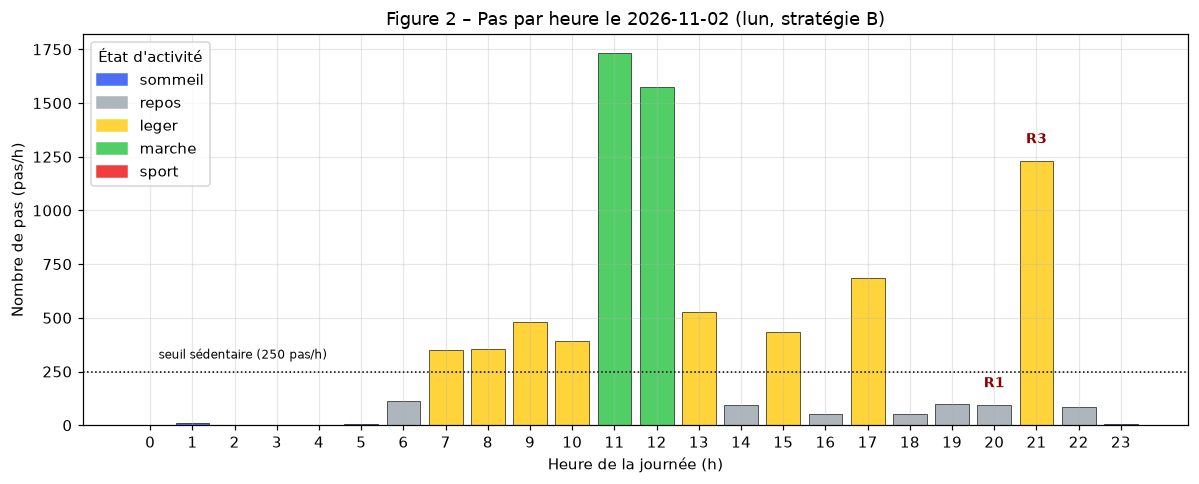

In [16]:
COULEURS_ETATS = {"sommeil": "#4c6ef5", "repos": "#adb5bd", "leger": "#ffd43b",
                  "marche": "#51cf66", "sport": "#f03e3e"}
j0 = df[df["date"] == jour_exemple]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(j0["heure"], j0["pas_nettoyes"], color=[COULEURS_ETATS[e] for e in j0["etat"]], edgecolor="black", lw=0.4)
ax.axhline(SEUIL_SEDENTAIRE, color="black", ls=":", lw=1)
ax.text(0.2, SEUIL_SEDENTAIRE + 60, "seuil sédentaire (250 pas/h)", fontsize=8)
for _, l in j0[j0["notification"] != ""].iterrows():
    ax.annotate(l["alerte"], (l["heure"], l["pas_nettoyes"]), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9, color="darkred", fontweight="bold")
ax.legend(handles=[mpatches.Patch(color=c, label=e) for e, c in COULEURS_ETATS.items()],
          title="État d'activité", loc="upper left")
ax.set_xticks(range(24))
ax.set_xlabel("Heure de la journée (h)"); ax.set_ylabel("Nombre de pas (pas/h)")
ax.set_title(f"Figure 2 – Pas par heure le {jour_exemple} ({j0['jour'].iloc[0]}, stratégie B)")
plt.tight_layout(); plt.savefig("figures/fig2_profil_horaire.png"); plt.show()

**Interprétation.** Le lundi 2 novembre, l'utilisateur dort jusqu'à 6h, puis l'activité se concentre sur deux pics de marche à 11h et 12h (pause déjeuner). L'après-midi et le début de soirée sont très calmes : de 18h à 20h il fait moins de 250 pas/h, ce qui déclenche l'**alerte d'inactivité R1 à 20h**. L'utilisateur réagit (≈ 1 200 pas à 21h au lieu de ≈ 600) et atteint l'objectif à 21h (**R3**). En stratégie A (sans notification), la même journée se termine à **7 691 pas** : l'objectif n'est pas atteint. Cet exemple montre la boucle complète capteur → décision → actionneur → effet sur l'utilisateur.

### 4.2 Progression vers l'objectif au cours de la journée

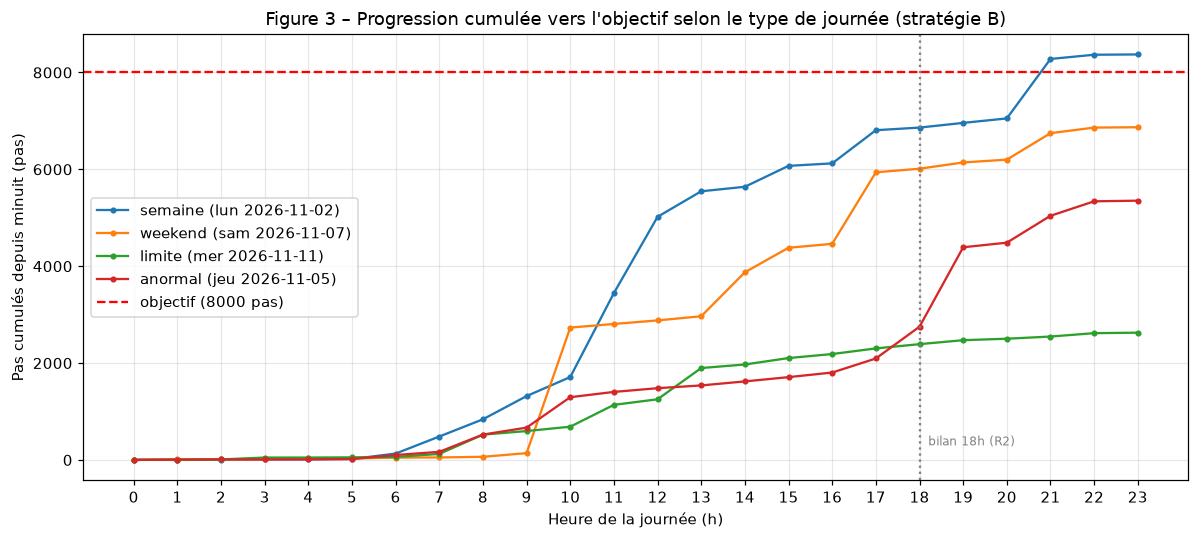

In [17]:
# Une journée de chaque type pour comparer
jours_compares = {
    "semaine": resume[resume["type_jour"] == "semaine"]["date"].iloc[0],
    "weekend": resume[resume["type_jour"] == "weekend"]["date"].iloc[0],
    "limite":  resume[resume["type_jour"] == "limite"]["date"].iloc[1],
    "anormal": resume[resume["type_jour"] == "anormal"]["date"].iloc[0],
}
fig, ax = plt.subplots(figsize=(11, 5))
for t, d in jours_compares.items():
    j = df[df["date"] == d]
    ax.plot(j["heure"], j["cumul"], marker="o", ms=3, label=f"{t} ({j['jour'].iloc[0]} {d})")
ax.axhline(OBJECTIF_QUOTIDIEN, color="red", ls="--", label=f"objectif ({OBJECTIF_QUOTIDIEN} pas)")
ax.axvline(HEURE_BILAN, color="gray", ls=":")
ax.text(HEURE_BILAN + 0.2, 300, "bilan 18h (R2)", color="gray", fontsize=8)
ax.set_xticks(range(24))
ax.set_xlabel("Heure de la journée (h)"); ax.set_ylabel("Pas cumulés depuis minuit (pas)")
ax.set_title("Figure 3 – Progression cumulée vers l'objectif selon le type de journée (stratégie B)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/fig3_progression.png"); plt.show()

**Interprétation.** Les courbes cumulées montrent *quand* l'activité a lieu. La journée de semaine monte surtout entre 10h et 13h puis à 17h et 21h. Le samedi démarre plus tard (presque aucun pas avant 10h) puis progresse par paliers liés aux sorties. La journée **limite** (révisions) reste presque plate : 2 628 pas seulement, soit 33 % de l'objectif. La journée **anormale** progresse à peine de 14h à 17h : c'est la panne de batterie, pas un vrai repos. À 18h le système ne compte que ≈ 1 840 pas valides (23 % de l'objectif) et envoie une alerte **R2 injustifiée** : une panne du capteur peut provoquer une mauvaise décision.

### 4.3 Comparaison des 14 journées

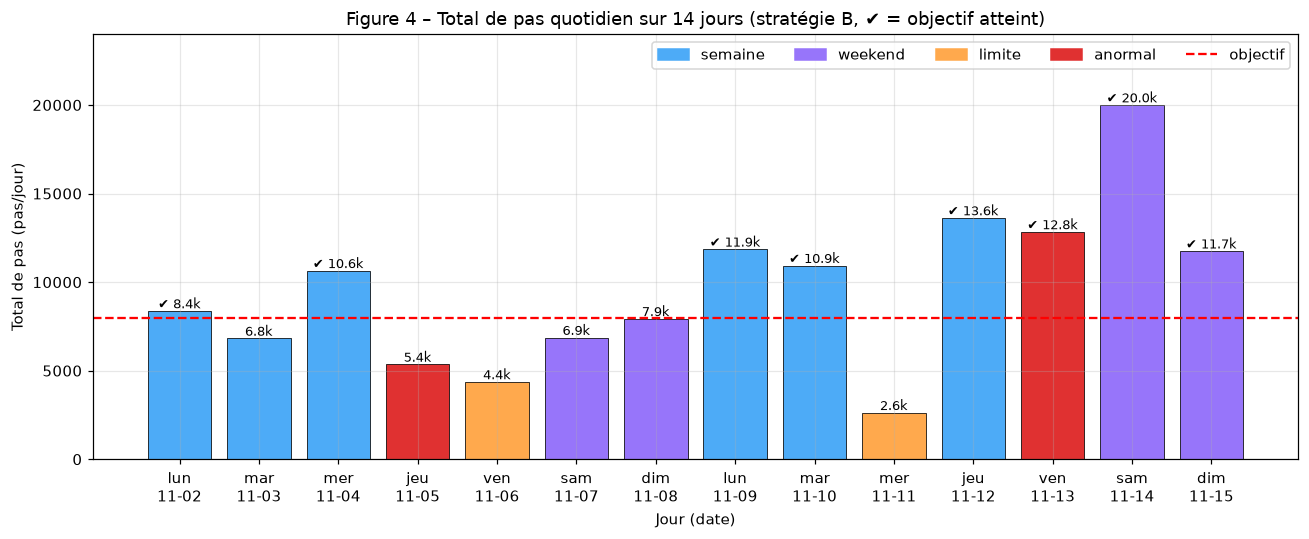

In [18]:
COULEURS_TYPES = {"semaine": "#4dabf7", "weekend": "#9775fa", "limite": "#ffa94d", "anormal": "#e03131"}
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(resume))
barres = ax.bar(x, resume["total_pas"], color=[COULEURS_TYPES[t] for t in resume["type_jour"]], edgecolor="black", lw=0.5)
ax.axhline(OBJECTIF_QUOTIDIEN, color="red", ls="--", lw=1.5)
for xi, (tot, ok) in enumerate(zip(resume["total_pas"], resume["objectif_atteint"])):
    ax.text(xi, tot + 150, ("✔ " if ok else "") + f"{tot/1000:.1f}k", ha="center", fontsize=8.5)
ax.set_xticks(x, [f"{j}\n{str(d)[5:]}" for j, d in zip(resume["jour"], resume["date"])])
ax.legend(handles=[mpatches.Patch(color=c, label=t) for t, c in COULEURS_TYPES.items()] +
          [plt.Line2D([], [], color="red", ls="--", label="objectif")], loc="upper right", ncol=5)
ax.set_xlabel("Jour (date)"); ax.set_ylabel("Total de pas (pas/jour)")
ax.set_ylim(0, resume["total_pas"].max() * 1.2)
ax.set_title("Figure 4 – Total de pas quotidien sur 14 jours (stratégie B, ✔ = objectif atteint)")
plt.tight_layout(); plt.savefig("figures/fig4_totaux_journaliers.png"); plt.show()

**Interprétation.** Sur 14 jours, l'objectif de 8 000 pas est atteint **8 fois** (57 %) en stratégie B. Les jours de semaine dépassent souvent l'objectif (trajets, pause déjeuner, sport le soir), alors que les deux journées **limites** (4 367 et 2 628 pas) sont très en dessous. Les week-ends sont les plus variables : de 6 869 pas (samedi 7) à 19 998 pas (samedi 14, avec deux séances de sport et de longues marches). La deuxième semaine est plus active que la première, ce qui justifie l'idée d'un objectif qui évolue (stratégie C).

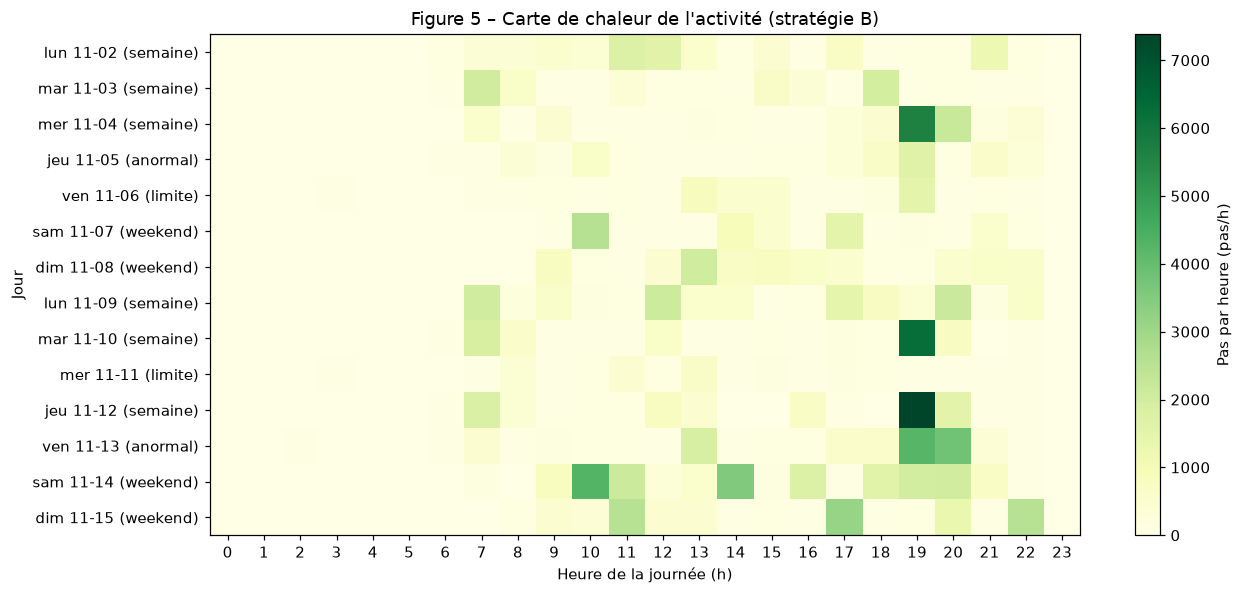

In [19]:
# Carte de chaleur : jours x heures
matrice = df.pivot(index="date", columns="heure", values="pas_nettoyes")
fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(matrice.values, aspect="auto", cmap="YlGn")
ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_yticks(range(len(matrice)))
ax.set_yticklabels([f"{j} {str(d)[5:]} ({t})" for j, d, t in zip(resume["jour"], resume["date"], resume["type_jour"])])
plt.colorbar(im, label="Pas par heure (pas/h)")
ax.set_xlabel("Heure de la journée (h)"); ax.set_ylabel("Jour")
ax.set_title("Figure 5 – Carte de chaleur de l'activité (stratégie B)")
ax.grid(False); plt.tight_layout(); plt.savefig("figures/fig5_heatmap.png"); plt.show()

**Interprétation.** La carte de chaleur résume les 336 mesures. On voit nettement la **nuit** (0h–6h, blanc), les **trajets** du matin et du soir en semaine, les **sorties de l'après-midi** le week-end et les deux journées limites, presque entièrement claires. Ce type de graphique permet de repérer les habitudes et de choisir les meilleurs moments pour envoyer une notification (par exemple 14h–16h en semaine, où l'utilisateur est souvent assis).

### 4.4 Détection et correction des anomalies du capteur

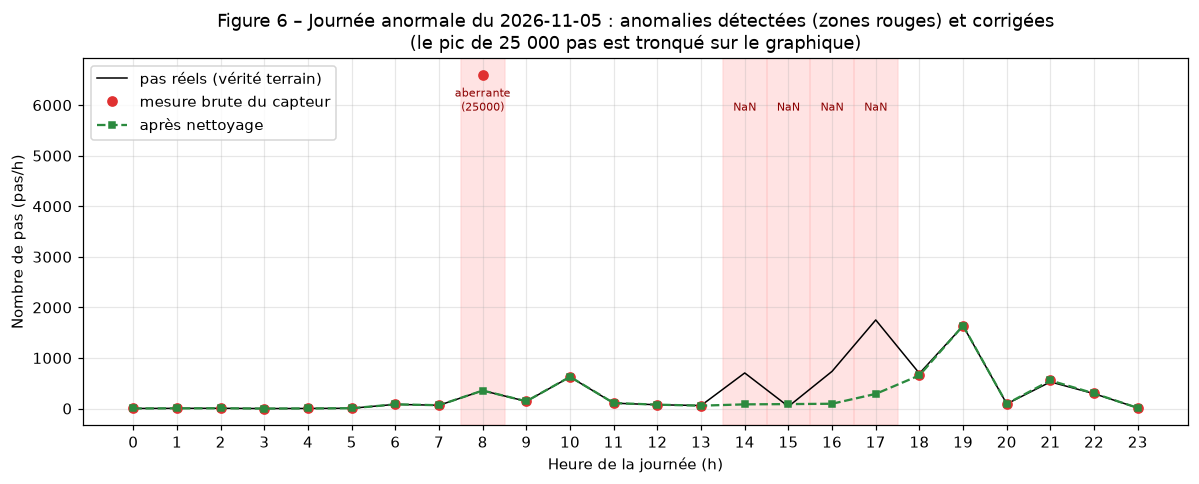

In [20]:
j_anormal = jours_compares["anormal"]
ja = df[df["date"] == j_anormal]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ja["heure"], ja["pas_reels"], "k-", lw=1, label="pas réels (vérité terrain)")
ax.plot(ja["heure"], ja["pas_mesures"].clip(upper=PAS_MAX_HORAIRE * 0.55), "o", color="#e03131",
        label="mesure brute du capteur")
ax.plot(ja["heure"], ja["pas_nettoyes"], "s--", color="#2b8a3e", ms=4, label="après nettoyage")
for _, l in ja[~ja["valide"]].iterrows():
    ax.axvspan(l["heure"] - 0.5, l["heure"] + 0.5, color="#ffc9c9", alpha=0.5)
    texte = "NaN" if pd.isna(l["pas_mesures"]) else f"{l['anomalie']}\n({int(l['pas_mesures'])})"
    ax.text(l["heure"], ax.get_ylim()[1] * 0.85, texte, ha="center", fontsize=7.5, color="darkred")
ax.set_xticks(range(24))
ax.set_xlabel("Heure de la journée (h)"); ax.set_ylabel("Nombre de pas (pas/h)")
ax.set_title(f"Figure 6 – Journée anormale du {j_anormal} : anomalies détectées (zones rouges) et corrigées\n"
             f"(le pic de 25 000 pas est tronqué sur le graphique)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.savefig("figures/fig6_anomalies.png"); plt.show()

**Interprétation.** Le système détecte **9 mesures invalides** sur 336 (2,7 %) : 7 manquantes, 1 aberrante (25 000 pas en 1 h, impossible) et 1 négative (le vendredi 13). Le pic aberrant de 8h est très bien corrigé par la médiane (356 pas estimés pour 355 réels). En revanche, pendant la panne de batterie, l'utilisateur marchait plus que d'habitude, et la médiane (≈ 80–290 pas/h) sous-estime fortement la réalité : le total nettoyé du 5 novembre est de **5 353 pas pour 8 021 pas réels (−33 %)**. Les autres jours, l'erreur reste inférieure à ±2,5 %. Le nettoyage par médiane élimine les valeurs impossibles, mais il ne peut pas « deviner » une activité inhabituelle pendant une panne.

### 4.5 Comparaison des stratégies A, B et C

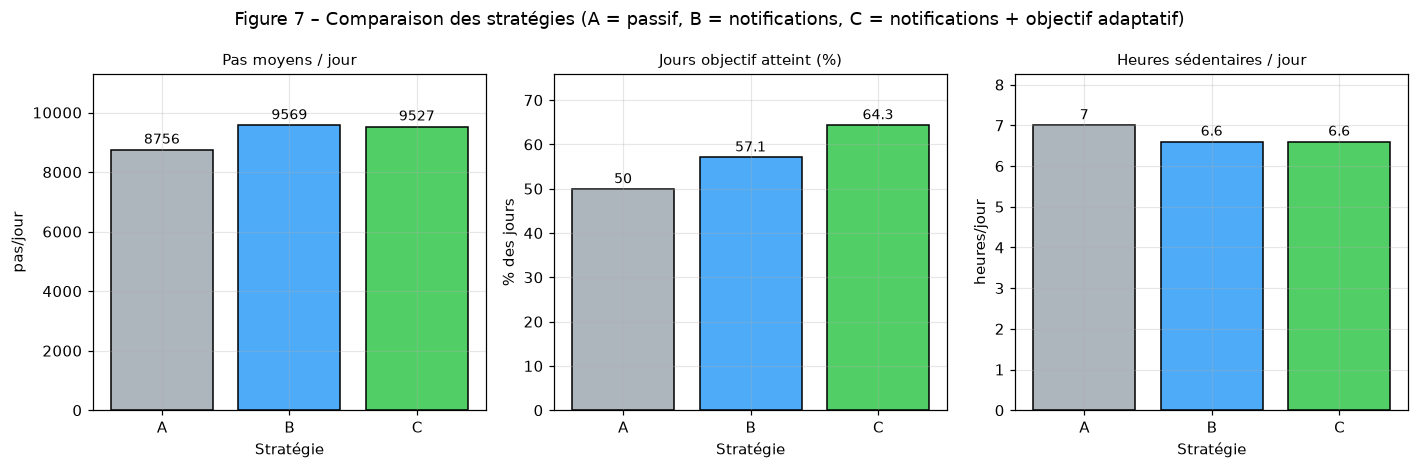

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
noms = list(sims)
couleurs = ["#adb5bd", "#4dabf7", "#51cf66"]
mesures = [("Pas moyens / jour", "pas/jour"),
           ("Jours objectif atteint (%)", "% des jours"),
           ("Heures sédentaires / jour", "heures/jour")]
for ax, (ind, unite) in zip(axes, mesures):
    valeurs = tableau_indicateurs.loc[ind, noms].astype(float)
    ax.bar(range(3), valeurs, color=couleurs, edgecolor="black")
    for i, v in enumerate(valeurs):
        ax.text(i, v * 1.01, f"{v:g}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3), [n.split(" - ")[0] for n in noms])
    ax.set_title(ind, fontsize=10); ax.set_ylabel(unite); ax.set_xlabel("Stratégie")
    ax.set_ylim(0, valeurs.max() * 1.18)
fig.suptitle("Figure 7 – Comparaison des stratégies (A = passif, B = notifications, C = notifications + objectif adaptatif)")
plt.tight_layout(); plt.savefig("figures/fig7_comparaison_strategies.png"); plt.show()

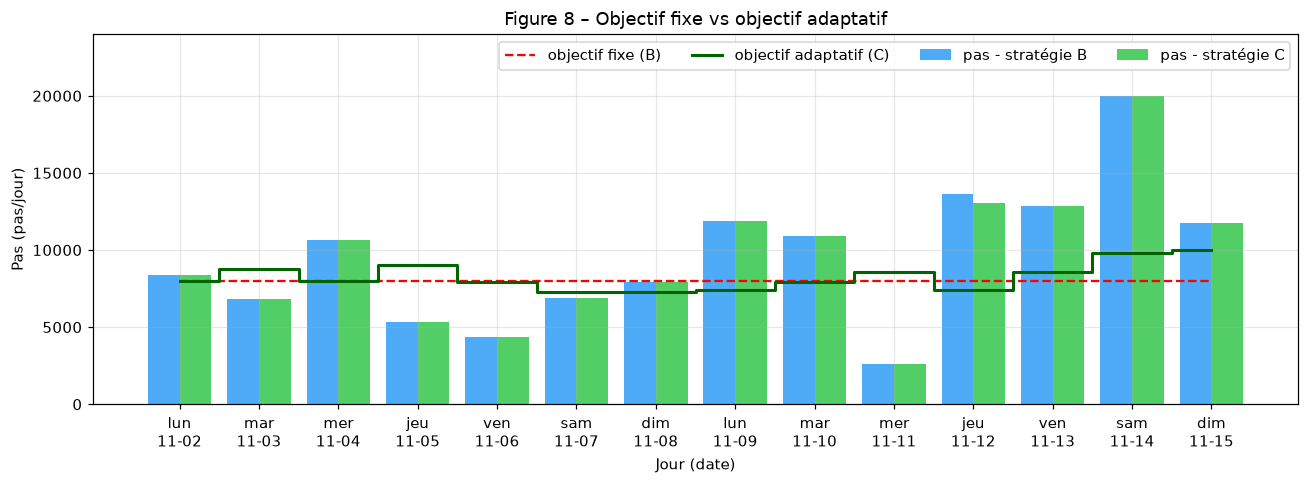

In [22]:
# Objectif fixe vs objectif adaptatif jour par jour
rB, rC = resumes["B - Notifications"], resumes["C - Notif. + adaptatif"]
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(rB))
ax.bar(x - 0.2, rB["total_pas"], 0.4, label="pas - stratégie B", color="#4dabf7")
ax.bar(x + 0.2, rC["total_pas"], 0.4, label="pas - stratégie C", color="#51cf66")
ax.step(x, rB["objectif"], where="mid", color="red", ls="--", label="objectif fixe (B)")
ax.step(x, rC["objectif"], where="mid", color="darkgreen", lw=2, label="objectif adaptatif (C)")
ax.set_xticks(x, [f"{j}\n{str(d)[5:]}" for j, d in zip(rB["jour"], rB["date"])])
ax.set_xlabel("Jour (date)"); ax.set_ylabel("Pas (pas/jour)")
ax.set_title("Figure 8 – Objectif fixe vs objectif adaptatif")
ax.legend(ncol=4, loc="upper right"); ax.set_ylim(0, max(rB["total_pas"].max(), rC["total_pas"].max()) * 1.2)
plt.tight_layout(); plt.savefig("figures/fig8_objectif_adaptatif.png"); plt.show()

**Interprétation des stratégies.**
- **A → B (notifications)** : la moyenne passe de **8 756 à 9 569 pas/jour (+9 %)**, le taux de jours réussis de **50 % à 57 %**, et les heures sédentaires baissent légèrement (7,0 → 6,6 h/jour). Le gain vient des réactions aux alertes R1 et R2 (environ 2,2 notifications par jour). Le lundi 2 bascule de « non atteint » à « atteint » grâce à une seule vibration.
- Les notifications sont **inutiles** les jours où l'utilisateur ne peut pas bouger : le mercredi 11 (révisions), 3 alertes ont été envoyées sans aucun effet.
- **B → C (objectif adaptatif)** : le nombre de pas est presque identique, mais le taux de réussite monte à **64 %**. L'objectif descend après une mauvaise semaine (7 300 pas le week-end du 7–8 novembre, ce qui rend le dimanche 8 réussi) et monte quand l'utilisateur progresse (jusqu'à la borne de 10 000 pas le dernier jour). L'objectif adaptatif est plus **motivant** (objectifs réalistes) mais un objectif plus bas peut aussi **réduire l'ambition** : un bon taux de réussite ne veut pas dire plus d'activité.

### 4.6 Tableau de bord journalier
Écran de synthèse de l'application pour une journée choisie (modifier `JOUR_TABLEAU`).

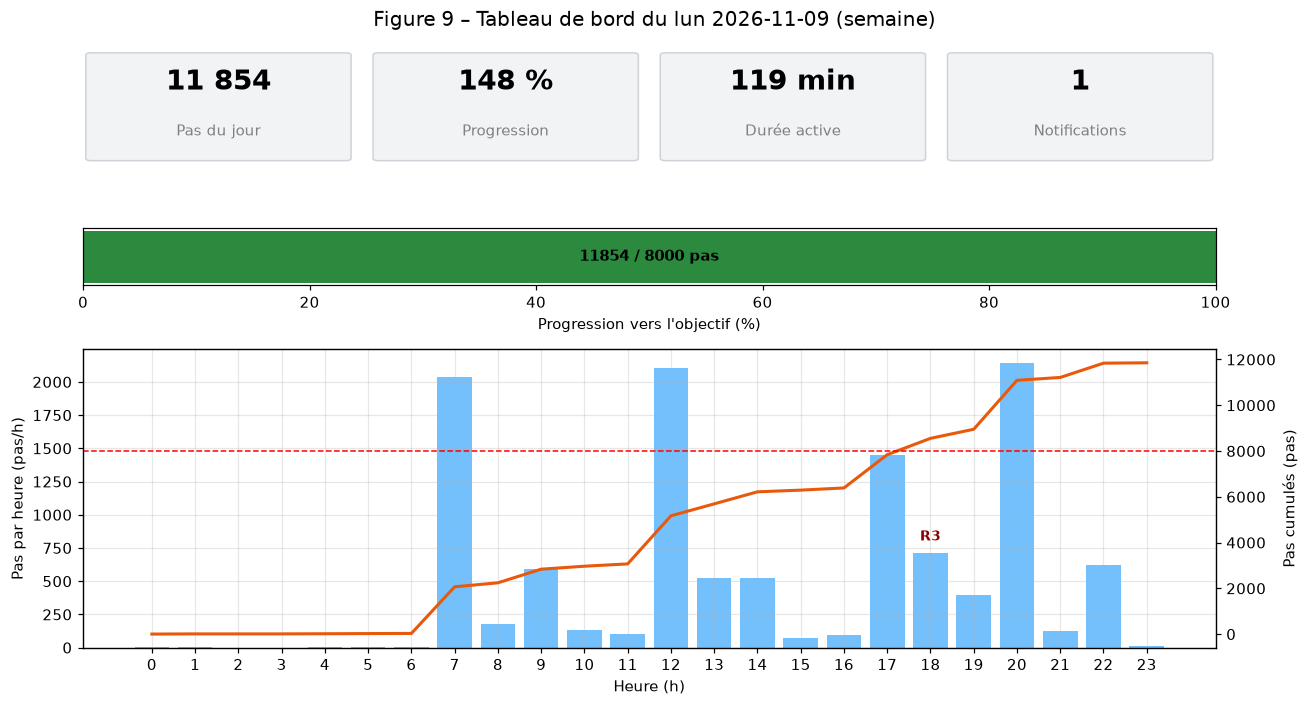

In [23]:
def tableau_de_bord(date, d=df):
    j = d[d["date"] == date]
    total, objectif = int(j["cumul"].iloc[-1]), int(j["objectif"].iloc[0])
    p = 100 * total / objectif
    fig = plt.figure(figsize=(12, 6.5))
    gs = fig.add_gridspec(3, 4, height_ratios=[1, 0.5, 2.6])
    kpis = [("Pas du jour", f"{total:,}".replace(",", " ")),
            ("Progression", f"{p:.0f} %"),
            ("Durée active", f"{j['minutes_actives'].sum():.0f} min"),
            ("Notifications", str(int((j['notification'] != '').sum())))]
    for i, (titre, val) in enumerate(kpis):
        a = fig.add_subplot(gs[0, i]); a.axis("off")
        a.add_patch(mpatches.FancyBboxPatch((0.03, 0.05), 0.94, 0.9, boxstyle="round,pad=0.02",
                                            fc="#f1f3f5", ec="#ced4da", transform=a.transAxes))
        a.text(0.5, 0.65, val, ha="center", fontsize=18, fontweight="bold", transform=a.transAxes)
        a.text(0.5, 0.25, titre, ha="center", fontsize=10, color="gray", transform=a.transAxes)
    a = fig.add_subplot(gs[1, :])
    a.barh([0], [100], color="#e9ecef"); a.barh([0], [min(p, 100)], color="#2b8a3e" if p >= 100 else "#fab005")
    a.set_xlim(0, 100); a.set_yticks([]); a.set_xlabel("Progression vers l'objectif (%)")
    a.text(min(p, 100) / 2, 0, f"{total} / {objectif} pas", ha="center", va="center", fontweight="bold")
    a.grid(False)
    a = fig.add_subplot(gs[2, :])
    a.bar(j["heure"], j["pas_nettoyes"], color="#74c0fc", label="pas par heure")
    a.set_xlabel("Heure (h)"); a.set_ylabel("Pas par heure (pas/h)"); a.set_xticks(range(24))
    a2 = a.twinx(); a2.plot(j["heure"], j["cumul"], color="#e8590c", lw=2, label="cumul")
    a2.axhline(objectif, color="red", ls="--", lw=1); a2.set_ylabel("Pas cumulés (pas)"); a2.grid(False)
    for _, l in j[j["notification"] != ""].iterrows():
        a.annotate(l["alerte"], (l["heure"], l["pas_nettoyes"]), xytext=(0, 8),
                   textcoords="offset points", ha="center", color="darkred", fontsize=9, fontweight="bold")
    fig.suptitle(f"Figure 9 – Tableau de bord du {j['jour'].iloc[0]} {date} ({j['type_jour'].iloc[0]})", fontsize=13)
    plt.tight_layout(); return fig

JOUR_TABLEAU = resume["date"].iloc[7]
tableau_de_bord(JOUR_TABLEAU); plt.savefig("figures/fig9_tableau_de_bord.png"); plt.show()

### 4.7 Sensibilité à l'objectif configurable
On fait varier `OBJECTIF_QUOTIDIEN` pour voir combien de jours il serait atteint (stratégie A, sans effet des notifications).

In [24]:
objectifs_testes = [5000, 6000, 7000, 8000, 9000, 10000, 12000]
totaux_A = resumes["A - Passif"]["total_pas"]
sensibilite = pd.DataFrame({
    "objectif (pas)": objectifs_testes,
    "jours atteints (%)": [round(100 * (totaux_A >= o).mean(), 1) for o in objectifs_testes],
})
sensibilite

,objectif (pas),jours atteints (%)
0,5000,85.7
1,6000,71.4
2,7000,64.3
3,8000,50.0
4,9000,35.7
5,10000,35.7
6,12000,21.4


**Interprétation.** Le choix de l'objectif change fortement le résultat : avec les mêmes données, 85,7 % des jours sont réussis à 5 000 pas, 50 % à 8 000 pas et seulement 21,4 % à 12 000 pas. Un objectif trop haut décourage, un objectif trop bas n'incite pas à bouger : c'est pour cela que l'objectif est **configurable** dans le programme (`OBJECTIF_QUOTIDIEN`).

## Interprétation globale, limites et améliorations

### Synthèse des résultats
| Indicateur | A – Passif | B – Notifications | C – Notif. + adaptatif |
|---|---|---|---|
| Pas moyens / jour | 8 756 | 9 569 | 9 527 |
| Jours objectif atteint | 50 % | 57,1 % | 64,3 % |
| Durée active moyenne | 87 min | 94 min | 94 min |
| Heures sédentaires / jour | 7,0 | 6,6 | 6,6 |
| Notifications / jour | 0 | 2,2 | 2,2 |

Le système IoT simulé remplit les fonctions demandées : génération de pas horaires, alternance repos/activité, total journalier, objectif configurable, affichage de la progression et tableau de bord. Les notifications augmentent l'activité de l'utilisateur simulé, et l'objectif adaptatif augmente le taux de réussite.

### Limites de la méthode
1. **Données entièrement simulées** : les probabilités d'activité et le taux de réaction (50 %) sont des hypothèses choisies par le groupe, pas des mesures réelles. Les gains des notifications dépendent directement de ces hypothèses.
2. **Résolution horaire** : avec un total par heure, on ne sait pas si 600 pas correspondent à 6 minutes de marche continue ou à des pas dispersés. La durée active (pas ÷ 100) n'est qu'une estimation.
3. **Un seul utilisateur et 14 jours** : les résultats varient avec la graine aléatoire ; il faudrait répéter la simulation (plusieurs graines, plusieurs profils) pour obtenir des moyennes fiables.
4. **Nettoyage limité** : la médiane sous-estime l'activité pendant une panne longue (−33 % le 5 novembre), et une panne peut provoquer une fausse alerte (R2 du 5 novembre).
5. **Comportement simplifié** : l'utilisateur ne se lasse jamais des notifications, alors qu'en réalité trop de vibrations finissent par être ignorées.

### Améliorations possibles
1. **Mesures à la minute + détection d'activité** : simuler les données de l'accéléromètre minute par minute et classer l'activité (marche, course, vélo) avec un algorithme simple (seuils sur la cadence) ou un petit modèle de machine learning ; la durée active serait alors mesurée et non estimée.
2. **Notifications intelligentes** : ne pas envoyer d'alerte quand le capteur est en panne (éviter les fausses alertes), limiter le nombre de vibrations par jour et choisir l'heure d'envoi à partir des habitudes de l'utilisateur.
3. **Tableau de bord interactif avec Streamlit** : permettre de choisir le jour, de modifier l'objectif avec un curseur et de voir la progression en direct.
4. **Plusieurs utilisateurs** : générer plusieurs profils (étudiant, employé de bureau, sportif) pour comparer les stratégies sur une population et non sur une seule personne.